# Cuaderno 03 · Reducción de dimensionalidad: ver un problema de 14 dimensiones
## Predicción de enfermedad cardiovascular — Proyecto final de Visualización de Datos

**Autor:** Omar Libardo Acelas Angulo · **Tutor:** Sergio Lara · Fundación Universitaria San Mateo · Octubre de 2026

---

### ¿Qué responde este cuaderno?

Cada paciente es un punto en un espacio de **14 dimensiones**, imposible de ver directamente. La reducción de dimensionalidad lo proyecta a 2 o 3 dimensiones conservando parte de su estructura. Usamos tres técnicas con filosofías distintas:

| Técnica | Qué conserva | Tipo | Advertencia de lectura |
|---|---|---|---|
| **PCA** | La varianza global (las direcciones de mayor dispersión) | Lineal | Puede ocultar estructura no lineal |
| **t-SNE** | Los vecindarios locales (quién está cerca de quién) | No lineal | Los tamaños de los grupos y las distancias entre ellos **no significan nada** |
| **UMAP** | Los vecindarios locales y parte de la estructura global | No lineal | Sensible a sus hiperparámetros |

Además de "ver" los datos, usamos las proyecciones para **ver al modelo**: dónde acierta, dónde se equivoca y por qué.

> 🧭 **Tiempo de ejecución:** unos 5 minutos en Colab (t-SNE se ejecuta cuatro veces).

In [1]:
# En Google Colab casi todo viene instalado; solo añadimos UMAP y SHAP si faltan.
import importlib, subprocess, sys
for paquete, modulo in [("umap-learn", "umap"), ("shap", "shap"), ("xgboost", "xgboost")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
print("Entorno listo")

Entorno listo


In [2]:
import warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEMILLA = 42                     # una sola semilla para todo el proyecto => resultados reproducibles
np.random.seed(SEMILLA)

# Paleta del proyecto: un color fijo por significado, el mismo en cuadernos y dashboard.
AZUL, NARANJA, AGUA = "#2a78d6", "#eb6834", "#1baf7a"   # sin ECV, con ECV, tercer modelo
GRIS, GRIS_OSCURO = "#c3c2b7", "#52514e"
COLOR_CLASE = {0: AZUL, 1: NARANJA}
NOMBRE_CLASE = {0: "Sin ECV", 1: "Con ECV"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "legend.frameon": False, "font.size": 10,
})
# ---------------------------------------------------------------------------
# RUTAS. Si el cuaderno está dentro de la carpeta Cardio360 (cuadernos/), trabaja con
# ../datos y ../resultados. En Colab, o suelto en otra carpeta, usa la carpeta actual.
# ---------------------------------------------------------------------------
RAIZ = ".." if os.path.isdir(os.path.join("..", "datos")) else "."
CARPETA_DATOS = os.path.join(RAIZ, "datos") if RAIZ == ".." else "."
RESULTADOS = os.path.join(RAIZ, "resultados")
os.makedirs(RESULTADOS, exist_ok=True)
RES = lambda nombre: os.path.join(RESULTADOS, nombre)
print("Modo:", "carpeta Cardio360 (datos/ y resultados/)" if RAIZ == ".." else "carpeta actual (Colab o archivo suelto)")

Modo: carpeta Cardio360 (datos/ y resultados/)


In [3]:
# ---------------------------------------------------------------------------
# PREPARACIÓN DE DATOS (idéntica en los tres cuadernos)
# Cada cuaderno puede ejecutarse solo en Colab; por eso repetimos aquí las reglas
# de limpieza decididas y justificadas en el Cuaderno 01.
# ---------------------------------------------------------------------------
URL_PROYECTO = "https://raw.githubusercontent.com/OmarLi-360/cardio360/main/datos/cardio_train.csv"
URL_DATOS = "https://raw.githubusercontent.com/caravanuden/cardio/master/cardio_train.csv"
URL_RESPALDO = ("https://raw.githubusercontent.com/kinir/catboost-with-pipelines/master/"
                "cardiovascular-disease-dataset/original/cardio_train.csv")
# Fuente original: Kaggle, "Cardiovascular Disease dataset" (Svetlana Ulianova).
# Copia del repositorio del proyecto + dos copias públicas, idénticas byte a byte (verificado con MD5).

def cargar_crudo():
    """Primero busca el archivo local (carpeta datos/ o carpeta actual); si no existe, lo descarga de GitHub."""
    for ruta in (os.path.join(CARPETA_DATOS, "cardio_train.csv"), "cardio_train.csv"):
        if os.path.exists(ruta):
            print("Datos leídos del archivo local:", ruta)
            return pd.read_csv(ruta, sep=";")
    for url in (URL_PROYECTO, URL_DATOS, URL_RESPALDO):
        try:
            datos_web = pd.read_csv(url, sep=";")
            print("Datos descargados de:", url)
            return datos_web
        except Exception as error:
            print(f"No se pudo leer {url}: {error}")
    raise RuntimeError("Sin acceso a los datos: copie cardio_train.csv en la carpeta datos/ (o súbalo a Colab) y vuelva a ejecutar.")

# Reglas en orden de aplicación: (nombre, justificación clínica, condición que CONSERVA la fila)
REGLAS = [
    ("Registros duplicados", "Mismo paciente registrado dos veces: inflaría el peso de esos casos.",
     lambda d: ~d.drop(columns="id").duplicated()),
    ("Sistólica fuera de 80–250 mmHg", "Por debajo de 80 o por encima de 250 no es compatible con un examen ambulatorio; son errores de digitación (p. ej. 1400 o -150).",
     lambda d: d["ap_hi"].between(80, 250)),
    ("Diastólica fuera de 40–160 mmHg", "Valores como 1000 o 0 son errores de captura, no mediciones.",
     lambda d: d["ap_lo"].between(40, 160)),
    ("Diastólica ≥ sistólica", "Fisiológicamente imposible: la presión diastólica siempre es menor que la sistólica (columnas invertidas).",
     lambda d: d["ap_lo"] < d["ap_hi"]),
    ("Altura fuera de 130–210 cm", "Adultos de 30 a 65 años; alturas de 55 cm o 250 cm son errores.",
     lambda d: d["height"].between(130, 210)),
    ("Peso fuera de 35–180 kg", "Extremos implausibles para la población estudiada.",
     lambda d: d["weight"].between(35, 180)),
    ("IMC fuera de 13–60", "Combinaciones altura-peso que producen un índice de masa corporal imposible.",
     lambda d: (d["weight"] / (d["height"] / 100) ** 2).between(13, 60)),
]

def limpiar(crudo):
    """Aplica las reglas en secuencia y devuelve los datos limpios y el embudo de limpieza."""
    datos, embudo = crudo.copy(), []
    for nombre, motivo, conservar in REGLAS:
        mascara = conservar(datos)
        embudo.append({"regla": nombre, "justificacion": motivo,
                       "eliminados": int((~mascara).sum()), "restantes": int(mascara.sum())})
        datos = datos[mascara]
    return datos.reset_index(drop=True), embudo

def categoria_presion(sis, dia):
    """Clasificación de presión arterial ACC/AHA 2017."""
    if sis > 180 or dia > 120: return "Crisis hipertensiva"
    if sis >= 140 or dia >= 90: return "HTA estadio 2"
    if sis >= 130 or dia >= 80: return "HTA estadio 1"
    if sis >= 120: return "Elevada"
    return "Normal"

ORDEN_PA = ["Normal", "Elevada", "HTA estadio 1", "HTA estadio 2", "Crisis hipertensiva"]

def derivar(datos):
    """Variables en unidades legibles + variables clínicas derivadas."""
    d = pd.DataFrame({
        "edad": (datos["age"] / 365.25).round(1),          # la edad viene en días
        "sexo": datos["gender"].map({1: "Mujer", 2: "Hombre"}),
        "altura": datos["height"], "peso": datos["weight"],
        "sistolica": datos["ap_hi"], "diastolica": datos["ap_lo"],
        "colesterol": datos["cholesterol"], "glucosa": datos["gluc"],
        "fuma": datos["smoke"], "alcohol": datos["alco"], "activo": datos["active"],
        "cardio": datos["cardio"],
    })
    d["imc"] = (d["peso"] / (d["altura"] / 100) ** 2).round(1)
    d["categoria_pa"] = pd.Categorical(
        [categoria_presion(s, di) for s, di in zip(d["sistolica"], d["diastolica"])],
        categories=ORDEN_PA, ordered=True)
    return d

# Variables que entran al modelo (colesterol y glucosa se codifican one-hot porque
# sus niveles 1-2-3 son categorías clínicas, no distancias numéricas).
VARIABLES = ["edad", "sexo_hombre", "altura", "peso", "imc", "sistolica", "diastolica",
             "colesterol_2", "colesterol_3", "glucosa_2", "glucosa_3", "fuma", "alcohol", "activo"]

def matriz_modelo(d):
    X = pd.DataFrame({
        "edad": d["edad"], "sexo_hombre": (d["sexo"] == "Hombre").astype(int),
        "altura": d["altura"], "peso": d["peso"], "imc": d["imc"],
        "sistolica": d["sistolica"], "diastolica": d["diastolica"],
        "colesterol_2": (d["colesterol"] == 2).astype(int), "colesterol_3": (d["colesterol"] == 3).astype(int),
        "glucosa_2": (d["glucosa"] == 2).astype(int), "glucosa_3": (d["glucosa"] == 3).astype(int),
        "fuma": d["fuma"], "alcohol": d["alcohol"], "activo": d["activo"],
    })[VARIABLES]
    return X, d["cardio"].values

crudo = cargar_crudo()
limpio, embudo = limpiar(crudo)
datos = derivar(limpio)
print(f"Registros originales: {len(crudo):,} | tras limpieza: {len(datos):,} "
      f"({len(datos)/len(crudo):.1%} conservado)")

Datos leídos del archivo local: ../datos/cardio_train.csv
Registros originales: 70,000 | tras limpieza: 68,512 (97.9% conservado)


## 1. Reproducir la partición y el modelo del Cuaderno 02

> 🧭 Usamos la **misma semilla y la misma partición**, así que el modelo es idéntico al del Cuaderno 02 sin necesidad de guardarlo y cargarlo. Los hiperparámetros son los que eligieron las curvas de validación de ese cuaderno.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
import umap, shap, time

# Hiperparámetros elegidos en el Cuaderno 02 (curvas de validación)
PROFUNDIDAD_XGB, C_LOGISTICA = 3, 0.01778279410038923

X, y = matriz_modelo(datos)
X_ent, X_pru, y_ent, y_pru, d_ent, d_pru = train_test_split(X, y, datos, test_size=0.2, stratify=y, random_state=SEMILLA)
modelo = XGBClassifier(n_estimators=300, max_depth=PROFUNDIDAD_XGB, learning_rate=0.05, subsample=0.8,
                       colsample_bytree=0.8, n_jobs=-1, random_state=SEMILLA, verbosity=0).fit(X_ent, y_ent)

escalador = StandardScaler().fit(X_ent)        # se ajusta SOLO con entrenamiento (evita fuga de información)
Z_ent, Z_pru = escalador.transform(X_ent), escalador.transform(X_pru)

# Muestra de 3.000 pacientes de prueba: la misma usada para SHAP en el Cuaderno 02.
muestra = X_pru.sample(3000, random_state=SEMILLA)
pos = X_pru.index.get_indexer(muestra.index)
Zm, ym = Z_pru[pos], y_pru[pos]
prob = modelo.predict_proba(muestra)[:, 1]
U_TAMIZAJE = 0.33
pred = (prob >= U_TAMIZAJE).astype(int)
resultado = np.select([(pred == 1) & (ym == 1), (pred == 0) & (ym == 0), (pred == 1) & (ym == 0)],
                      ["VP", "VN", "FP"], "FN")
print("Muestra:", Zm.shape, "| Distribución de resultados (umbral 0,33):", dict(zip(*np.unique(resultado, return_counts=True))))

Muestra: (3000, 14) | Distribución de resultados (umbral 0,33): {np.str_('FN'): np.int64(191), np.str_('FP'): np.int64(698), np.str_('VN'): np.int64(852), np.str_('VP'): np.int64(1259)}


> 🧭 **Por qué estandarizar antes de reducir.** PCA, t-SNE y UMAP trabajan con distancias. Sin estandarizar, la sistólica (rango de 160 mmHg) dominaría sobre las variables binarias (rango de 1) solo por su escala, no por su importancia.

## 2. PCA: ¿cuánta información cabe en pocas dimensiones?

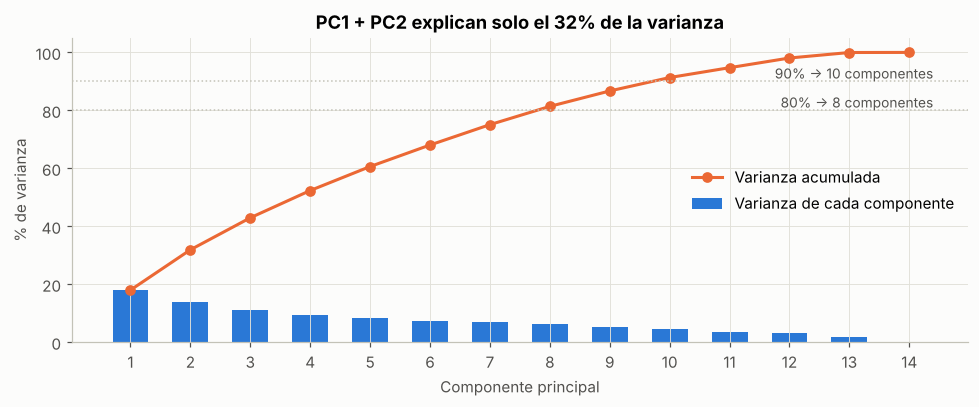

In [5]:
pca_completo = PCA(random_state=SEMILLA).fit(Z_ent)
varianza = pca_completo.explained_variance_ratio_
acumulada = np.cumsum(varianza)
n80, n90 = int(np.argmax(acumulada >= 0.8) + 1), int(np.argmax(acumulada >= 0.9) + 1)

fig, ax = plt.subplots(figsize=(9, 3.8))
comp = np.arange(1, len(varianza) + 1)
ax.bar(comp, varianza * 100, color=AZUL, width=0.6, label="Varianza de cada componente")
ax.plot(comp, acumulada * 100, color=NARANJA, marker="o", lw=2, label="Varianza acumulada")
for umbral, n in [(80, n80), (90, n90)]:
    ax.axhline(umbral, color=GRIS, ls=":", lw=1)
    ax.text(14.4, umbral + 1, f"{umbral}% → {n} componentes", ha="right", fontsize=9, color=GRIS_OSCURO)
ax.set(xlabel="Componente principal", ylabel="% de varianza", xticks=comp, ylim=(0, 105),
       title=f"PC1 + PC2 explican solo el {acumulada[1]:.0%} de la varianza")
ax.legend(loc="center right"); plt.tight_layout(); plt.show()

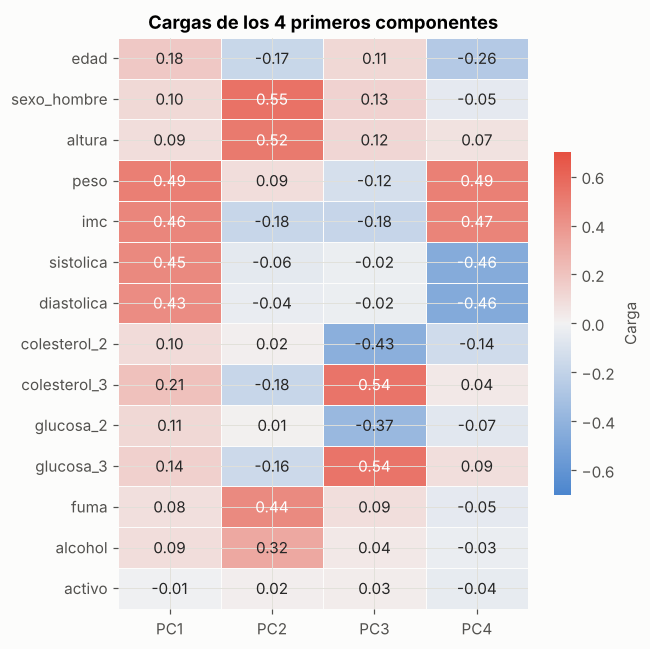

In [6]:
# Cargas (loadings): qué variables forman cada componente. Así PCA deja de ser una caja negra.
cargas = pd.DataFrame(pca_completo.components_[:4].T, index=VARIABLES, columns=[f"PC{i}" for i in range(1, 5)])
fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(cargas, cmap=sns.diverging_palette(250, 15, s=75, l=55, as_cmap=True), center=0, vmin=-0.7, vmax=0.7,
            annot=True, fmt=".2f", linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"shrink": 0.6, "label": "Carga"}, ax=ax)
ax.set_title("Cargas de los 4 primeros componentes"); plt.tight_layout(); plt.show()

> 🧭 **Lectura de PCA**
> - **La información está repartida.** Los dos primeros componentes explican solo el **32 %** de la varianza, y se necesitan **8 de 14** para llegar al 80 %. No hay una "dirección dominante": las variables aportan información poco redundante.
> - **PC1, "carga cardiometabólica":** peso, IMC, sistólica y diastólica cargan juntos. Es el eje que más se alinea con la enfermedad, y por eso en PCA los naranjas se cargan hacia un lado.
> - **PC2, "eje del sexo":** sexo masculino, altura, tabaco y alcohol. Recoge que en estos datos los hombres son más altos y reportan fumar y beber más, no algo sobre la enfermedad.
> - **PC3, "eje metabólico":** contrasta colesterol y glucosa *muy altos* contra *altos*.

## 3. Las tres proyecciones

> 🧭 **Hiperparámetros elegidos.** Para t-SNE, una **perplejidad de 30** (aproximadamente cuántos vecinos considera cada punto). Para UMAP, **15 vecinos** y una distancia mínima de 0,1. Son los valores recomendados por los autores de cada método; en la sección 5 mostramos qué pasa al cambiarlos.

In [7]:
proyecciones, tiempos = {}, {}
t0 = time.time(); pca2 = PCA(n_components=3, random_state=SEMILLA).fit(Z_ent)
proyecciones["PCA"] = pca2.transform(Zm); tiempos["PCA"] = time.time() - t0
t0 = time.time()
proyecciones["t-SNE"] = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEMILLA).fit_transform(Zm)
tiempos["t-SNE"] = time.time() - t0
t0 = time.time()
proyecciones["UMAP"] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit_transform(Zm)
tiempos["UMAP"] = time.time() - t0
print({k: f"{v:.1f}s" for k, v in tiempos.items()})

{'PCA': '0.0s', 't-SNE': '11.5s', 'UMAP': '23.9s'}


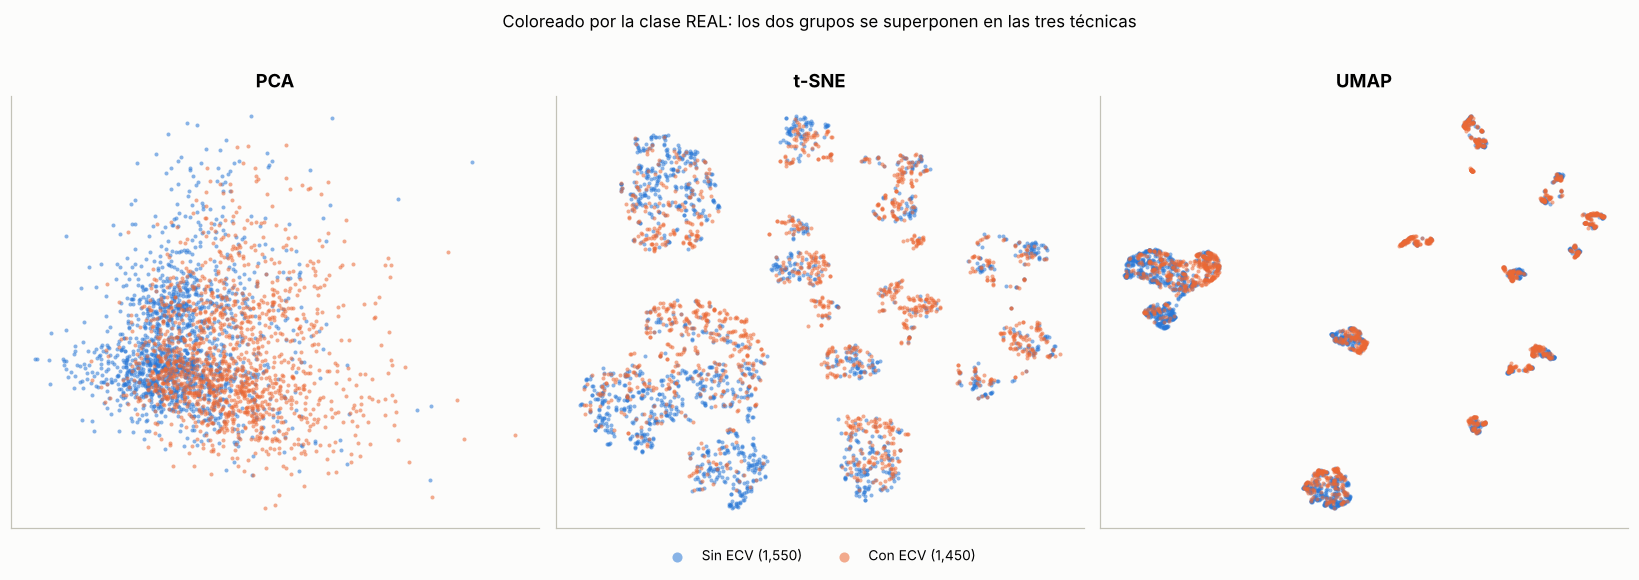

In [8]:
def panel(color_de, titulo, leyenda):
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, (metodo, P) in zip(ejes, proyecciones.items()):
        for valor, color, rotulo in leyenda:
            m = color_de == valor
            ax.scatter(P[m, 0], P[m, 1], s=7, color=color, alpha=0.55, label=f"{rotulo} ({m.sum():,})", linewidths=0)
        ax.set_title(metodo); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    manejadores, rotulos = ejes[0].get_legend_handles_labels()
    fig.legend(manejadores, rotulos, loc="lower center", ncol=len(leyenda), markerscale=2.5, fontsize=9, bbox_to_anchor=(0.5, -0.06))
    plt.suptitle(titulo, y=1.01, fontsize=11); plt.tight_layout(); plt.show()

panel(ym, "Coloreado por la clase REAL: los dos grupos se superponen en las tres técnicas",
      [(0, AZUL, "Sin ECV"), (1, NARANJA, "Con ECV")])

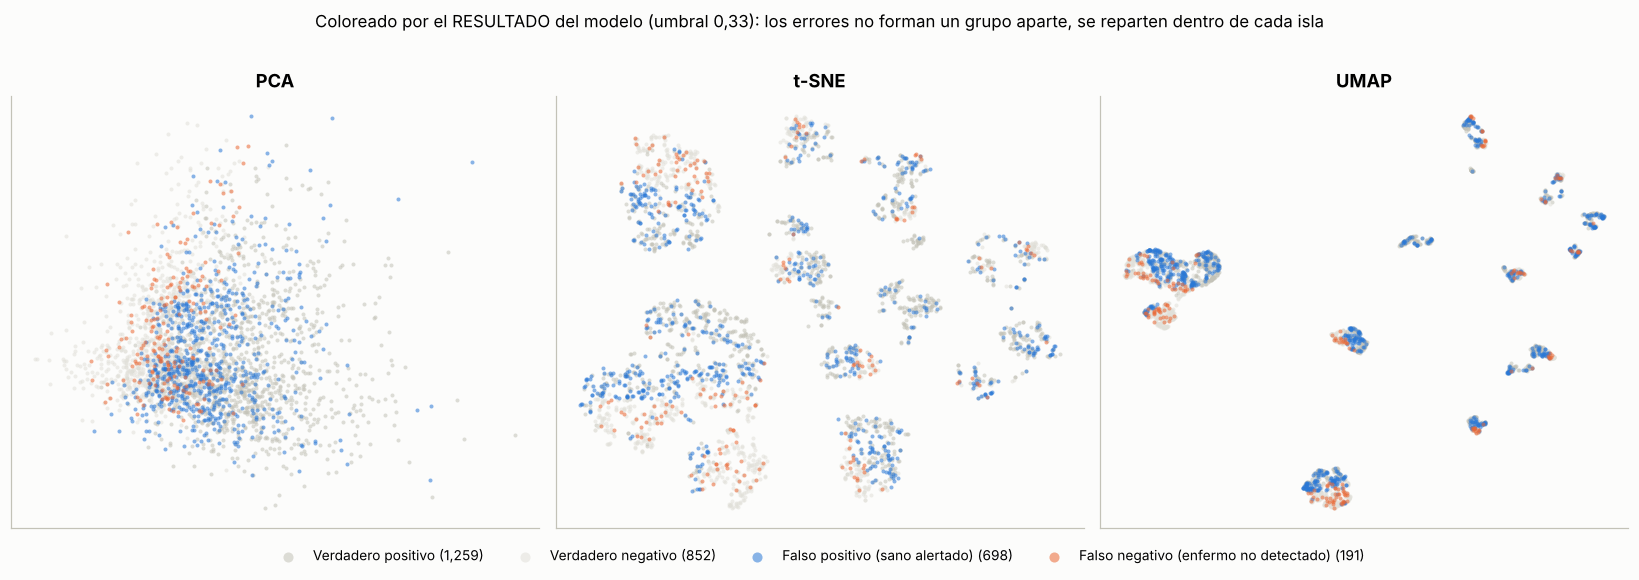

In [9]:
panel(resultado, "Coloreado por el RESULTADO del modelo (umbral 0,33): los errores no forman un grupo aparte, se reparten dentro de cada isla",
      [("VP", GRIS, "Verdadero positivo"), ("VN", "#e1e0d9", "Verdadero negativo"),
       ("FP", AZUL, "Falso positivo (sano alertado)"), ("FN", NARANJA, "Falso negativo (enfermo no detectado)")])

## 4. ¿Qué forma los grupos que vemos?

Las proyecciones no lineales muestran **islas** bien separadas, pero no corresponden a la enfermedad. Coloreemos por otras variables para descubrir qué las forma.

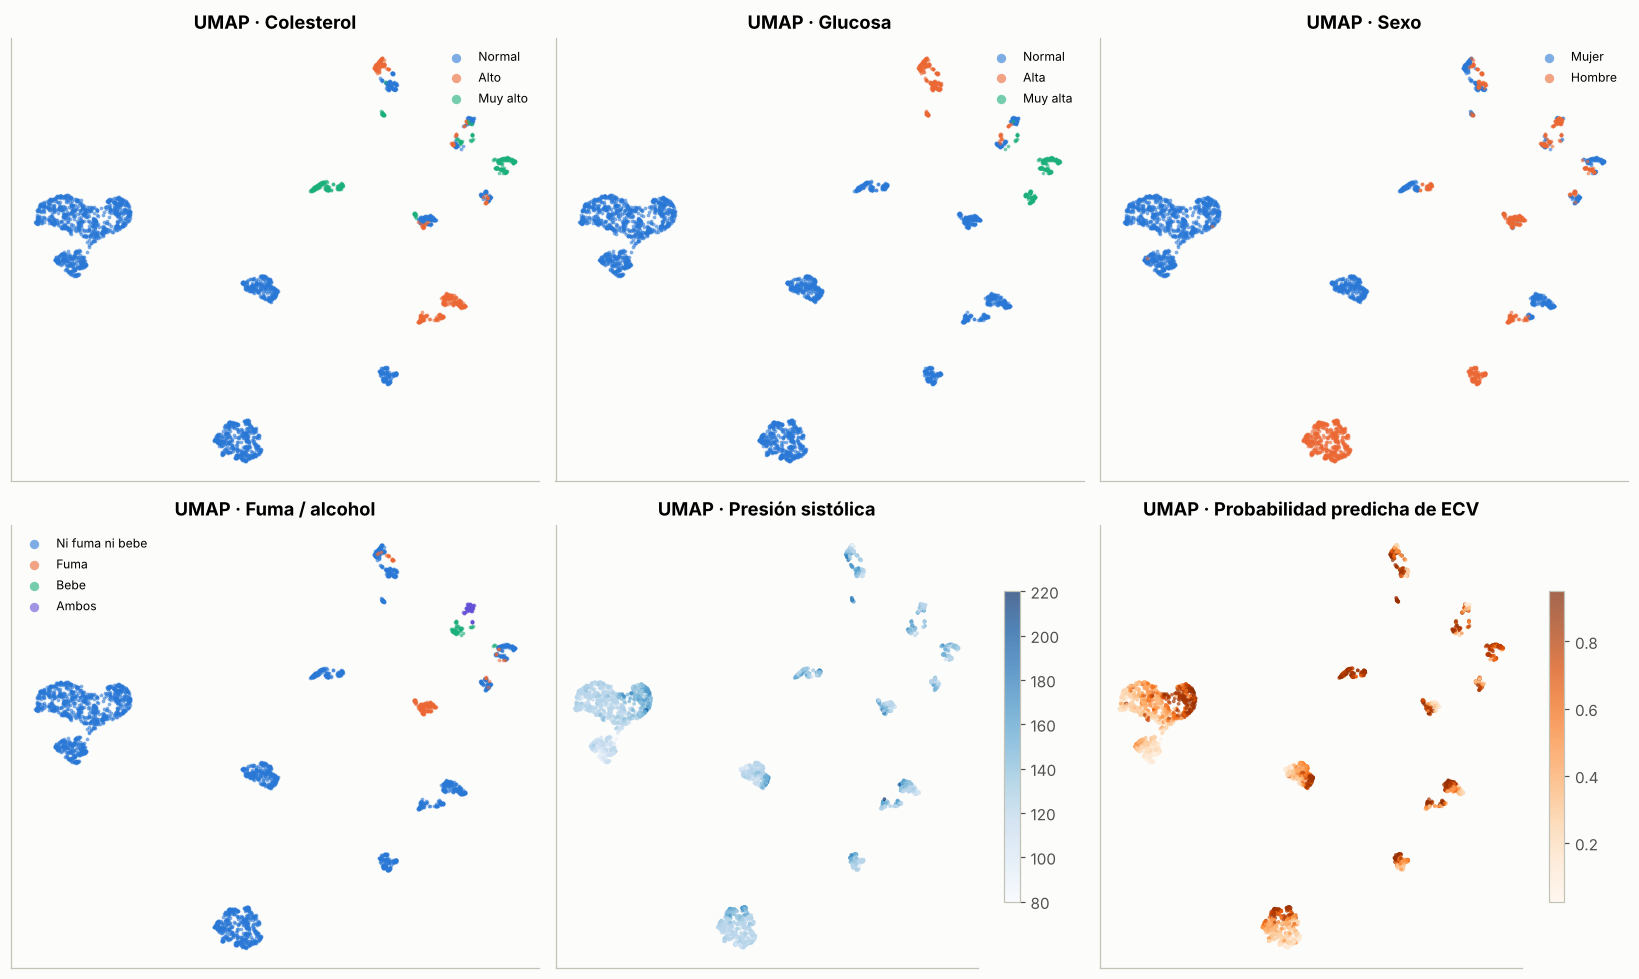

In [10]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
P = proyecciones["UMAP"]
coloreos = [("Colesterol", muestra["colesterol_2"] + 2 * muestra["colesterol_3"], "cat", {0: "Normal", 1: "Alto", 2: "Muy alto"}),
            ("Glucosa", muestra["glucosa_2"] + 2 * muestra["glucosa_3"], "cat", {0: "Normal", 1: "Alta", 2: "Muy alta"}),
            ("Sexo", muestra["sexo_hombre"], "cat", {0: "Mujer", 1: "Hombre"}),
            ("Fuma / alcohol", muestra["fuma"] * 1 + muestra["alcohol"] * 2, "cat", {0: "Ni fuma ni bebe", 1: "Fuma", 2: "Bebe", 3: "Ambos"}),
            ("Presión sistólica", muestra["sistolica"], "cont", None),
            ("Probabilidad predicha de ECV", pd.Series(prob, index=muestra.index), "cont", None)]
paleta_cat = [AZUL, NARANJA, AGUA, "#6250d6"]
for ax, (titulo, valores, tipo, etiquetas) in zip(ejes.flat, coloreos):
    if tipo == "cat":
        for k, (v, et) in enumerate(etiquetas.items()):
            m = (valores == v).values
            ax.scatter(P[m, 0], P[m, 1], s=6, color=paleta_cat[k], alpha=0.6, label=et, linewidths=0)
        ax.legend(markerscale=2.5, fontsize=8, loc="best")
    else:
        sc = ax.scatter(P[:, 0], P[:, 1], s=6, c=valores, cmap="Blues" if "Pres" in titulo else "Oranges", alpha=0.7, linewidths=0)
        plt.colorbar(sc, ax=ax, shrink=0.7)
    ax.set_title(f"UMAP · {titulo}"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

> 🧭 **Lectura: las islas no son tipos de paciente**
> - Las islas de t-SNE y UMAP corresponden a **combinaciones de variables categóricas**: sexo × nivel de colesterol × nivel de glucosa × tabaco/alcohol. Una isla puede ser, por ejemplo, "mujeres con colesterol y glucosa normales que no fuman".
> - **Dentro de cada isla, las dos clases están mezcladas.** Lo que varía dentro de una isla es la **presión y la probabilidad predicha**, que forman un degradado.
> - **Lección para la sustentación:** ver grupos bien separados en t-SNE o UMAP **no prueba** que existan "subtipos" de enfermedad. Antes de interpretar una isla hay que preguntarse qué variable la forma. Aquí son las variables binarias, que crean saltos de distancia artificiales.

## 5. Sensibilidad a los hiperparámetros

> 🧭 **Lección metodológica.** Una proyección no es "la" forma de los datos: es **una** vista que depende de cómo se configure el método. Mostrarlo evita sobreinterpretar.

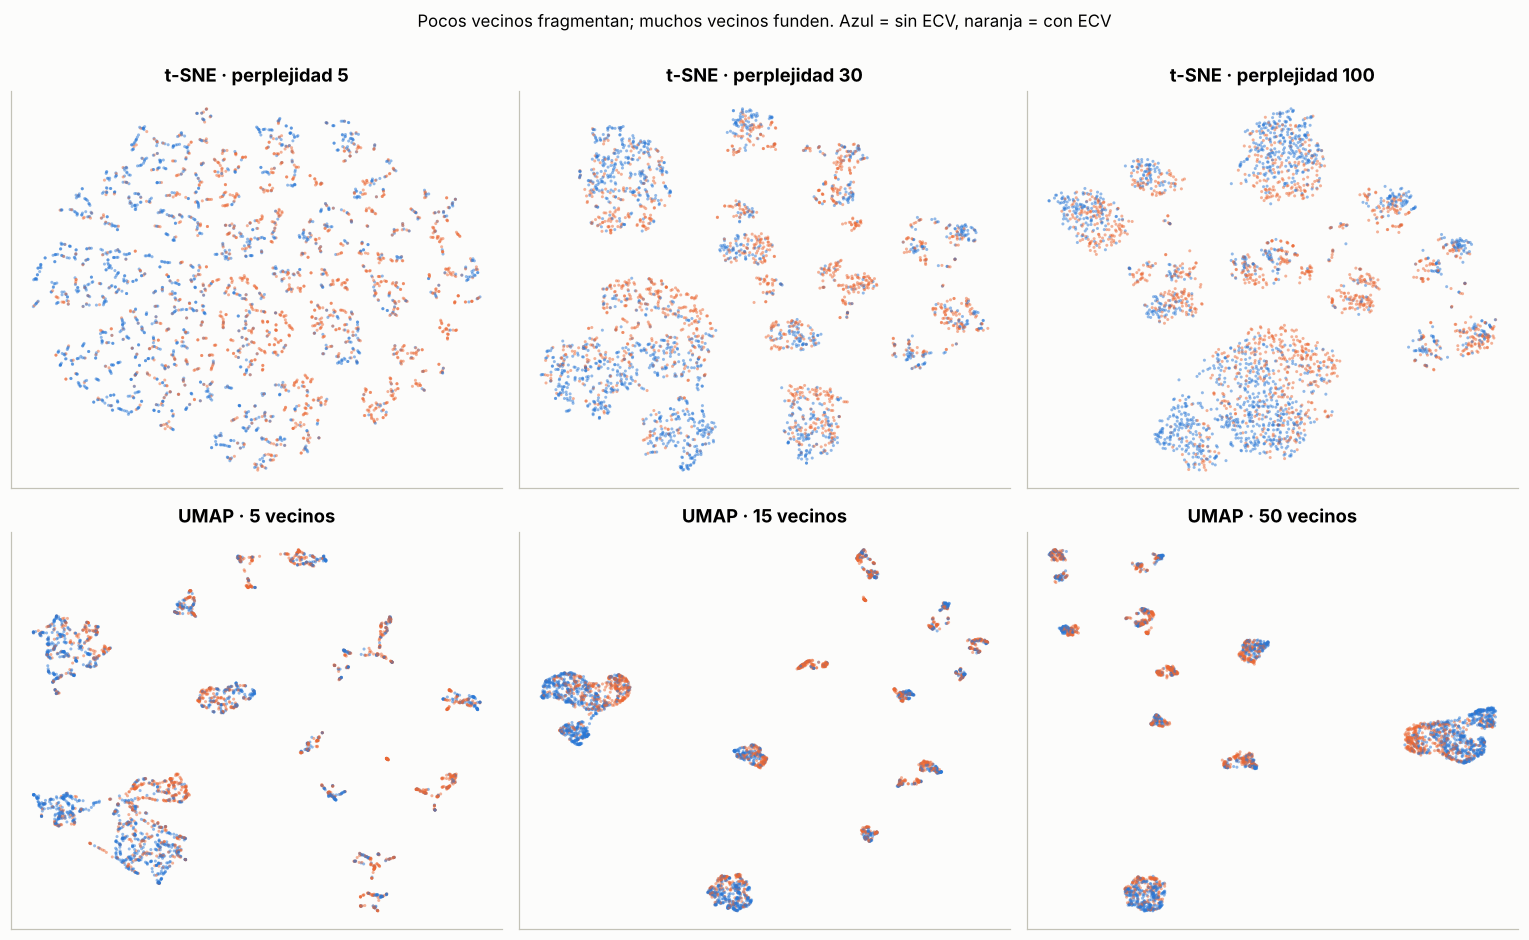

In [11]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, perp in zip(ejes[0], [5, 30, 100]):
    E = TSNE(n_components=2, perplexity=perp, init="pca", random_state=SEMILLA).fit_transform(Zm)
    ax.scatter(E[:, 0], E[:, 1], s=4, c=[COLOR_CLASE[v] for v in ym], alpha=0.5, linewidths=0)
    ax.set_title(f"t-SNE · perplejidad {perp}")
for ax, vecinos in zip(ejes[1], [5, 15, 50]):
    E = umap.UMAP(n_neighbors=vecinos, min_dist=0.1, random_state=SEMILLA).fit_transform(Zm)
    ax.scatter(E[:, 0], E[:, 1], s=4, c=[COLOR_CLASE[v] for v in ym], alpha=0.5, linewidths=0)
    ax.set_title(f"UMAP · {vecinos} vecinos")
for ax in ejes.flat: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("Pocos vecinos fragmentan; muchos vecinos funden. Azul = sin ECV, naranja = con ECV", y=1.0, fontsize=11)
plt.tight_layout(); plt.show()

## 6. Medir cuánta información se pierde

Dos métricas cuantitativas, para no quedarnos solo con la impresión visual:
- **Confiabilidad (*trustworthiness*):** de 0 a 1, mide si los vecinos en 2D también eran vecinos en 14D. Penaliza los "falsos vecindarios".
- **AUC de un clasificador k-NN:** se entrena un clasificador de vecinos cercanos sobre la proyección 2D y se compara con el mismo clasificador en las 14 dimensiones originales. La diferencia mide cuánta **información predictiva** se perdió al comprimir.

In [12]:
knn = KNeighborsClassifier(n_neighbors=25)
calidad = {"14D original": {"confiabilidad": 1.0,
           "auc_knn": cross_val_score(knn, Zm, ym, cv=5, scoring="roc_auc").mean()}}
for metodo, P in proyecciones.items():
    P2 = P[:, :2]
    calidad[metodo] = {"confiabilidad": trustworthiness(Zm, P2, n_neighbors=15),
                       "auc_knn": cross_val_score(knn, P2, ym, cv=5, scoring="roc_auc").mean()}
tabla_calidad = pd.DataFrame(calidad).T.round(3)
tabla_calidad.columns = ["Confiabilidad (k=15)", "AUC k-NN (5 pliegues)"]
tabla_calidad

,Confiabilidad (k=15),AUC k-NN (5 pliegues)
14D original,1.000,0.779
PCA,0.745,0.751
t-SNE,0.991,0.760
UMAP,0.982,0.758


> 🧭 **Lectura de las métricas**
> - **t-SNE (0,991) y UMAP (0,982)** conservan casi perfectamente los vecindarios locales, que es justo para lo que están diseñados. **PCA (0,745)** los distorsiona más, porque prioriza la varianza global.
> - **Comprimir a 2D casi no destruye información predictiva.** Un k-NN en 14 dimensiones logra un AUC de **0,779**, y en las proyecciones 2D logra entre 0,751 y 0,760.
> - **Conclusión clave:** la mezcla de clases que vemos en las proyecciones **no es un artefacto de la reducción**. Las clases ya se superponen en el espacio original, y eso explica el techo de AUC ≈ 0,80 que encontramos en el Cuaderno 02. La visualización y el modelo cuentan la misma historia.

## 7. Exploración interactiva en Colab (vista previa del dashboard)

Pase el cursor sobre los puntos para ver los datos de cada paciente. En el dashboard HTML, además, al hacer clic se abre la **explicación SHAP** de la predicción.

In [13]:
import plotly.express as px
vista = muestra.assign(x=proyecciones["UMAP"][:, 0], y=proyecciones["UMAP"][:, 1], probabilidad=prob.round(3),
                       clase=[NOMBRE_CLASE[v] for v in ym], resultado=resultado)
fig = px.scatter(vista, x="x", y="y", color="resultado", opacity=0.7,
                 color_discrete_map={"VP": GRIS, "VN": "#e1e0d9", "FP": AZUL, "FN": NARANJA},
                 hover_data={"edad": True, "sistolica": True, "diastolica": True, "imc": ":.1f",
                             "probabilidad": True, "clase": True, "x": False, "y": False},
                 title="UMAP interactivo · resultado del modelo con umbral 0,33", height=550)
fig.update_traces(marker=dict(size=5)); fig.update_xaxes(visible=False); fig.update_yaxes(visible=False)
fig.show()

In [14]:
fig = px.scatter_3d(x=proyecciones["PCA"][:, 0], y=proyecciones["PCA"][:, 1], z=proyecciones["PCA"][:, 2],
                    color=[NOMBRE_CLASE[v] for v in ym], opacity=0.6, height=550,
                    color_discrete_map={"Sin ECV": AZUL, "Con ECV": NARANJA},
                    labels={"x": "PC1", "y": "PC2", "z": "PC3"}, title="PCA en 3 dimensiones (arrastre para rotar)")
fig.update_traces(marker=dict(size=2.5)); fig.show()

## 8. Exportar resultados para el dashboard

> 🧭 Exportamos las coordenadas de las tres proyecciones, los datos clínicos y los **valores SHAP de cada paciente**. Así, en el dashboard, un clic sobre un punto muestra *por qué* el modelo le asignó ese riesgo. Es la unión de la reducción de dimensionalidad con la explicabilidad.

In [15]:
explicador = shap.TreeExplainer(modelo)
sv = explicador(muestra)
redondear = lambda a, k=3: np.round(np.asarray(a, dtype=float), k).tolist()
latente = {
    "n": int(len(muestra)), "umbral": U_TAMIZAJE, "variables": VARIABLES,
    "coords": {"PCA": redondear(proyecciones["PCA"]), "t-SNE": redondear(proyecciones["t-SNE"]),
               "UMAP": redondear(proyecciones["UMAP"])},
    "real": ym.tolist(), "prob": redondear(prob, 4),
    "pacientes": {c: (muestra[c].round(1) if c in ("edad", "imc", "peso") else muestra[c]).tolist() for c in VARIABLES},
    "shap": redondear(sv.values, 4), "shap_base": round(float(np.ravel(sv.base_values)[0]), 4),
    "pca": {"varianza": redondear(varianza, 4), "acumulada": redondear(acumulada, 4),
            "cargas": {c: redondear(cargas[c]) for c in cargas.columns}},
    "calidad": {k: {"confiabilidad": round(float(v["confiabilidad"]), 4), "auc_knn": round(float(v["auc_knn"]), 4)}
                for k, v in calidad.items()},
}
with open(RES("latente.json"), "w", encoding="utf-8") as f:
    json.dump(latente, f, ensure_ascii=False)
ARCHIVOS_EXPORTADOS = [RES("latente.json")]
print(f"latente.json: {os.path.getsize(RES('latente.json'))/1024:.0f} KB")

latente.json: 722 KB


In [16]:
# Descarga de resultados (solo en Colab). Estos JSON alimentan el dashboard interactivo.
try:
    from google.colab import files
    for archivo in ARCHIVOS_EXPORTADOS:
        files.download(archivo)
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta", RESULTADOS)

Fuera de Colab: los archivos quedaron en la carpeta ../resultados


## Cierre del proyecto

| Pregunta | Respuesta corta |
|---|---|
| ¿Qué tan bien se predice la ECV? | AUC de 0,80. El techo lo ponen las variables, no el algoritmo ni la cantidad de datos. |
| ¿Qué la predice? | Sobre todo la presión sistólica, seguida de la edad y el colesterol muy alto. |
| ¿Se separan visualmente los grupos? | No: en 2D las clases se mezclan, y en esa zona de mezcla viven los errores del modelo. |
| ¿Es equitativo? | Por sexo, sí. Por edad, no con un umbral único. |

👉 Todos estos resultados se exploran de forma interactiva en el **dashboard HTML** del proyecto.